# Preprocessing For the Customer Segmentation

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import  category_encoders as ce

# the Segmentation is the Target and the other columns are the features

In [61]:
train=pd.read_csv('Train.csv')

In [62]:
test=pd.read_csv('Test.csv')

# Data cleaning, and undertanding it

In [63]:
train.head()


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


In [64]:
train.describe()

,ID,Age,Work_Experience,Family_Size
count,8068.000000,8068.000000,7239.000000,7733.000000
mean,463479.214551,43.466906,2.641663,2.850123
std,2595.381232,16.711696,3.406763,1.531413
min,458982.000000,18.000000,0.000000,1.000000
25%,461240.750000,30.000000,0.000000,2.000000
50%,463472.500000,40.000000,1.000000,3.000000
75%,465744.250000,53.000000,4.000000,4.000000
max,467974.000000,89.000000,14.000000,9.000000


In [65]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 918.9 KB


In [66]:
test.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,B
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,A
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6,A
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,B
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6,A


In [67]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2627 entries, 0 to 2626
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2627 non-null   int64  
 1   Gender           2627 non-null   str    
 2   Ever_Married     2577 non-null   str    
 3   Age              2627 non-null   int64  
 4   Graduated        2603 non-null   str    
 5   Profession       2589 non-null   str    
 6   Work_Experience  2358 non-null   float64
 7   Spending_Score   2627 non-null   str    
 8   Family_Size      2514 non-null   float64
 9   Var_1            2595 non-null   str    
 10  Segmentation     2627 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 299.1 KB


In [68]:
test.describe()

,ID,Age,Work_Experience,Family_Size
count,2627.000000,2627.000000,2358.000000,2514.000000
mean,463433.918919,43.649791,2.552587,2.825378
std,2618.245698,16.967015,3.341094,1.551906
min,458989.000000,18.000000,0.000000,1.000000
25%,461162.500000,30.000000,0.000000,2.000000
50%,463379.000000,41.000000,1.000000,2.000000
75%,465696.000000,53.000000,4.000000,4.000000
max,467968.000000,89.000000,14.000000,9.000000


In [69]:
train.drop(['ID'],axis=1,inplace=True)
test.drop('ID',axis=1,inplace=True)

In [70]:
train.reset_index(drop=True,inplace=True)
test.reset_index(drop=True,inplace=True)

In [71]:
train.isnull().sum().sort_values(ascending=False)

Work_Experience    829
Family_Size        335
Ever_Married       140
Profession         124
Graduated           78
Var_1               76
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64

In [72]:
test.isnull().sum().sort_values(ascending=False)

Work_Experience    269
Family_Size        113
Ever_Married        50
Profession          38
Var_1               32
Graduated           24
Gender               0
Age                  0
Spending_Score       0
Segmentation         0
dtype: int64

In [73]:
train.duplicated().sum()

np.int64(417)

In [74]:
train.drop_duplicates(inplace=True)


In [75]:
train.duplicated().sum()

np.int64(0)

In [76]:
test.duplicated().sum()

np.int64(22)

In [77]:
test.drop_duplicates(inplace=True)

In [78]:
test.duplicated().sum()

np.int64(0)

In [79]:
train.select_dtypes('number').columns

Index(['Age', 'Work_Experience', 'Family_Size'], dtype='str')

<Axes: ylabel='Frequency'>

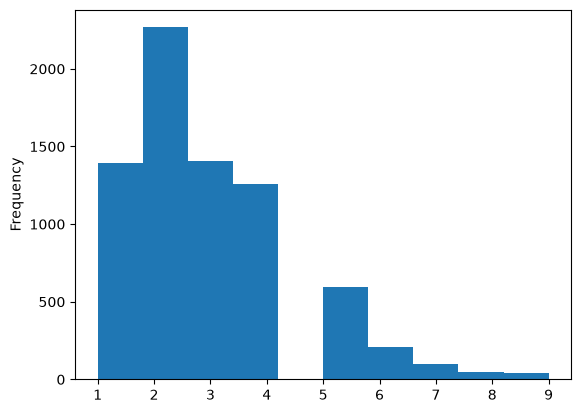

In [80]:
train['Family_Size'].plot(kind='hist')

In [81]:
train['Family_Size'].skew() # we will use the most frequent or the median

np.float64(1.0272277875946603)

<Axes: ylabel='Frequency'>

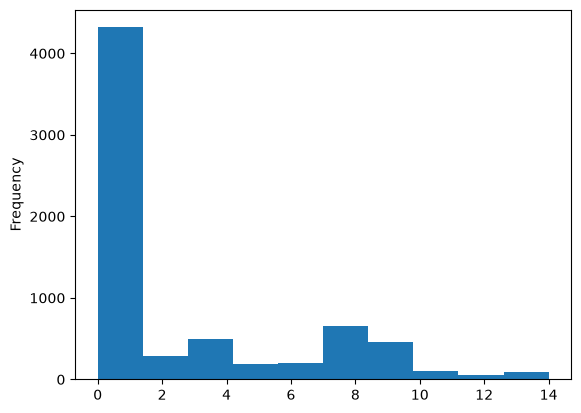

In [82]:
train['Work_Experience'].plot(kind='hist')

In [83]:
train['Work_Experience'].skew() # we will use the most frequent or the median

np.float64(1.2519544933391553)

In [84]:
from sklearn.impute import SimpleImputer
imputer= SimpleImputer(missing_values=np.nan,strategy='median')
train[['Family_Size']]=imputer.fit_transform(train[['Family_Size']])
test[['Family_Size']]= imputer.transform(test[['Family_Size']])


In [85]:
from sklearn.impute import SimpleImputer
imputer= SimpleImputer(missing_values=np.nan,strategy='median')
train[['Work_Experience']]=imputer.fit_transform(train[['Work_Experience']])
test[['Work_Experience']]= imputer.transform(test[['Work_Experience']])

In [86]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for col in ['Ever_Married','Graduated','Profession','Var_1']:
     imputer.fit(train[[col]])
     train[[col]]=imputer.transform(train[[col]])
     test[[col]]=imputer.transform(test[[col]])
      

In [87]:
train.isnull().sum().sort_values(ascending=False)

Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64

In [88]:
test.isnull().sum().sort_values(ascending=False)

Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
Segmentation       0
dtype: int64

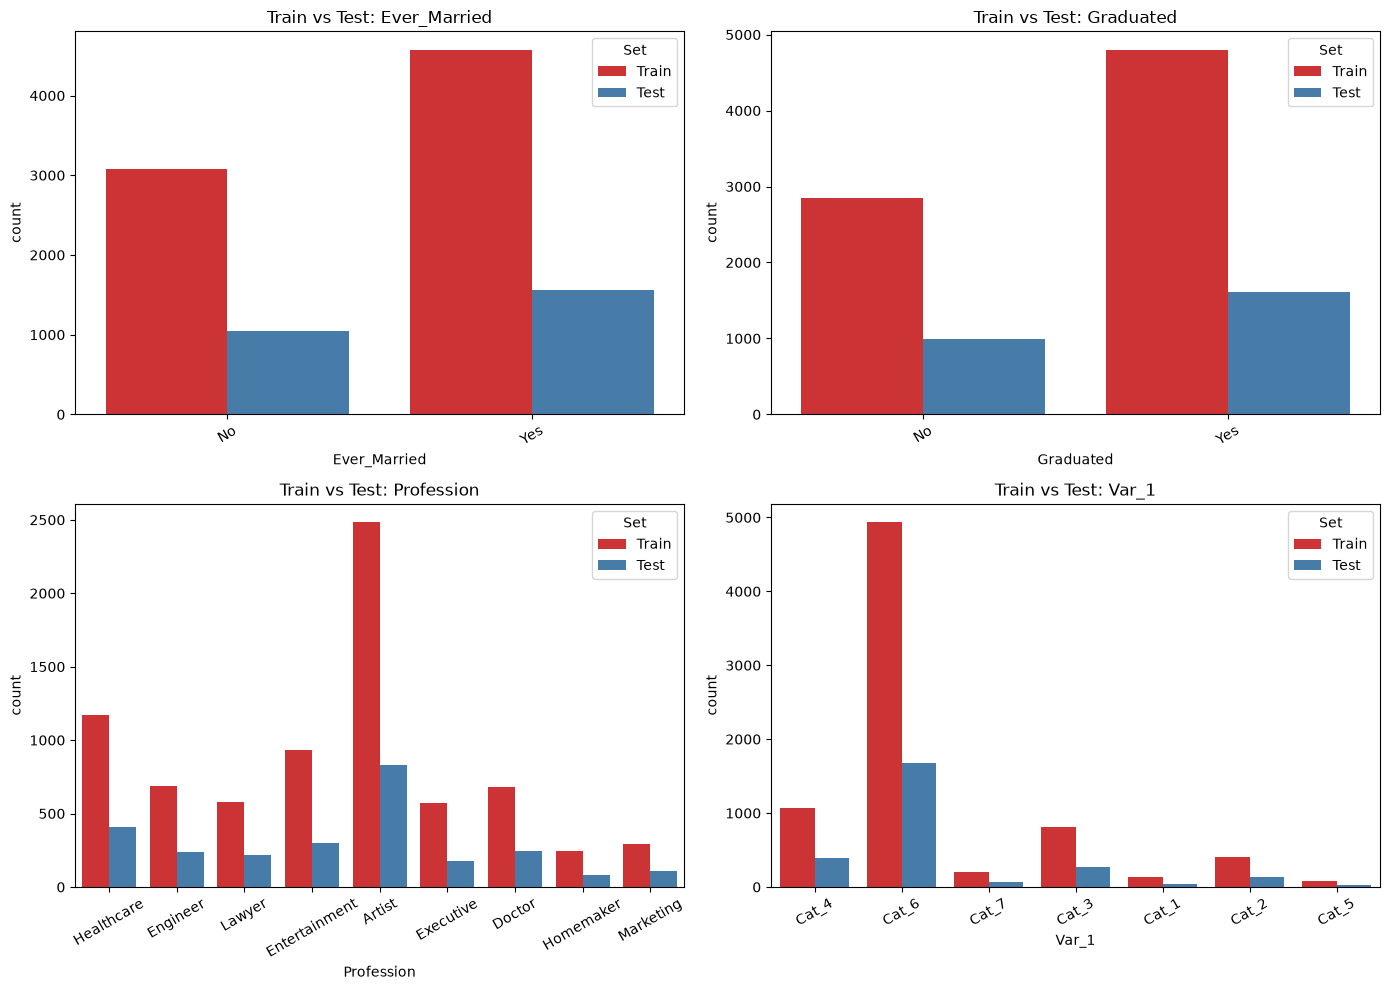

In [89]:

train['Set'] = 'Train'
test['Set'] = 'Test'
combined_df = pd.concat([train, test], axis=0).reset_index(drop=True)

cat_cols = ['Ever_Married', 'Graduated', 'Profession', 'Var_1']


plt.figure(figsize=(14, 10))
for i, col in enumerate(cat_cols, 1):
    plt.subplot(2, 2, i)
    sns.countplot(data=combined_df, x=col, hue='Set', palette='Set1')
    plt.title(f'Train vs Test: {col}')
    plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

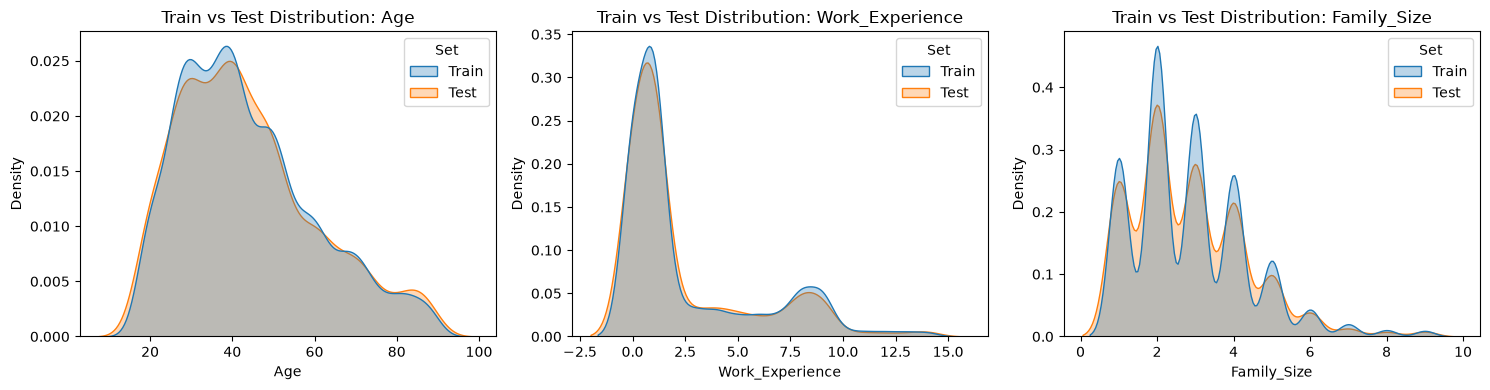

In [90]:

num_cols = ['Age', 'Work_Experience', 'Family_Size']
num_cols = [col for col in num_cols if col in combined_df.columns]

plt.figure(figsize=(15, 4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    sns.kdeplot(data=combined_df, x=col, hue='Set', common_norm=False, fill=True, alpha=0.3)
    plt.title(f'Train vs Test Distribution: {col}')

plt.tight_layout()
plt.show()

# Encoding and Scaling

In [91]:
train.select_dtypes('object').columns

C:\Users\abdoa\AppData\Local\Temp\ipykernel_15532\1552401917.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train.select_dtypes('object').columns


Index(['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score',
       'Var_1', 'Segmentation', 'Set'],
      dtype='str')

In [92]:
train.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Set
0,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D,Train
1,Female,Yes,38,Yes,Engineer,1.0,Average,3.0,Cat_4,A,Train
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B,Train
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B,Train
4,Female,Yes,40,Yes,Entertainment,1.0,High,6.0,Cat_6,A,Train


In [93]:
train.drop('Set',axis=1,inplace=True)

In [94]:
test.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Set
0,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,B,Test
1,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,A,Test
2,Female,Yes,69,No,Artist,0.0,Low,1.0,Cat_6,A,Test
3,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,B,Test
4,Female,No,19,No,Marketing,1.0,Low,4.0,Cat_6,A,Test


In [95]:
test.drop('Set',axis=1,inplace=True)

In [96]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder(sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

In [97]:
ohe_cols = ['Gender', 'Ever_Married', 'Graduated', 'Profession']

ohe = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')
ohe.fit(train[ohe_cols])

ohe_train_encoded = pd.DataFrame(ohe.transform(train[ohe_cols]), columns=ohe.get_feature_names_out(ohe_cols))
ohe_test_encoded = pd.DataFrame(ohe.transform(test[ohe_cols]), columns=ohe.get_feature_names_out(ohe_cols))

In [98]:
train = pd.concat([train.drop(columns=ohe_cols).reset_index(drop=True), ohe_train_encoded], axis=1)
test = pd.concat([test.drop(columns=ohe_cols).reset_index(drop=True), ohe_test_encoded], axis=1)

In [99]:
train.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,22,1.0,Low,4.0,Cat_4,D,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,38,1.0,Average,3.0,Cat_4,A,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,67,1.0,Low,1.0,Cat_6,B,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,67,0.0,High,2.0,Cat_6,B,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,40,1.0,High,6.0,Cat_6,A,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [100]:
test.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,36,0.0,Low,1.0,Cat_6,B,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,37,8.0,Average,4.0,Cat_6,A,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,69,0.0,Low,1.0,Cat_6,A,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,59,11.0,High,2.0,Cat_6,B,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,19,1.0,Low,4.0,Cat_6,A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [101]:

from sklearn.preprocessing import LabelEncoder

spending_map = {'Low': 0, 'Average': 1, 'High': 2}
train['Spending_Score'] = train['Spending_Score'].map(spending_map)
test['Spending_Score'] = test['Spending_Score'].map(spending_map)

train['Var_1'] = train['Var_1'].str.replace('Cat_', '').astype(float)
test['Var_1'] = test['Var_1'].str.replace('Cat_', '').astype(float)

le = LabelEncoder()
train['Segmentation'] = le.fit_transform(train['Segmentation'])

In [102]:
train.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,22,1.0,0,4.0,4.0,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,38,1.0,1,3.0,4.0,0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,67,1.0,0,1.0,6.0,1,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,67,0.0,2,2.0,6.0,1,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,40,1.0,2,6.0,6.0,0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [103]:
test.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,36,0.0,0,1.0,6.0,B,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,37,8.0,1,4.0,6.0,A,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,69,0.0,0,1.0,6.0,A,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,59,11.0,2,2.0,6.0,B,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,19,1.0,0,4.0,6.0,A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


<function matplotlib.pyplot.show(close=None, block=None)>

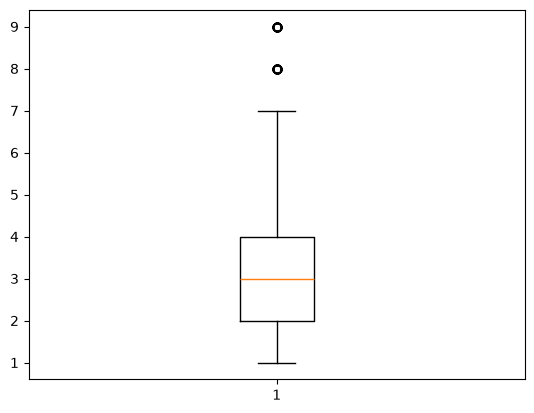

In [104]:
plt.boxplot(train['Family_Size'])
plt.show

In [105]:
def remove_outliers_iqr(data, column_name='value'):
    Q1 = train[column_name].quantile(0.25)
    Q3 = train[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return train[(train[column_name] >= lower) & (train[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(train, column_name='Family_Size')

print(train.shape, cleaned_df.shape)


(7651, 17) (7557, 17)


<function matplotlib.pyplot.show(close=None, block=None)>

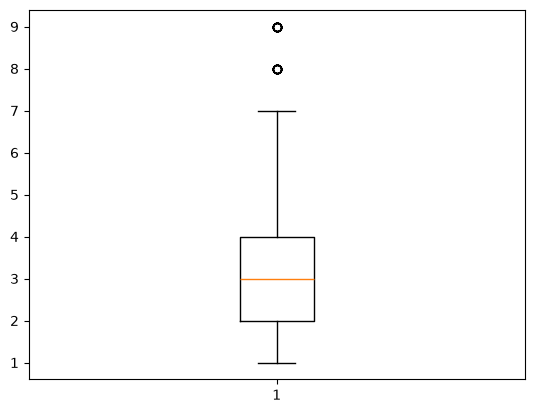

In [106]:
plt.boxplot(test['Family_Size'])
plt.show

In [107]:
def remove_outliers_iqr(data, column_name='value'):
    Q1 = test[column_name].quantile(0.25)
    Q3 = test[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return test[(train[column_name] >= lower) & (test[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(test, column_name='Family_Size')

print(test.shape, cleaned_df.shape)


(2605, 17) (2574, 17)


C:\Users\abdoa\AppData\Local\Temp\ipykernel_15532\819203980.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  return test[(train[column_name] >= lower) & (test[column_name] <= upper)]


<function matplotlib.pyplot.show(close=None, block=None)>

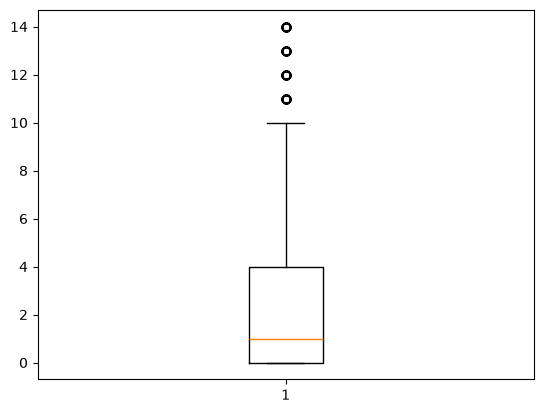

In [108]:
plt.boxplot(train['Work_Experience'])
plt.show

In [109]:
def remove_outliers_iqr(data, column_name='value'):
    Q1 = train[column_name].quantile(0.25)
    Q3 = train[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return train[(train[column_name] >= lower) & (train[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(train, column_name='Work_Experience')

print(train.shape, cleaned_df.shape)


(7651, 17) (7462, 17)


<function matplotlib.pyplot.show(close=None, block=None)>

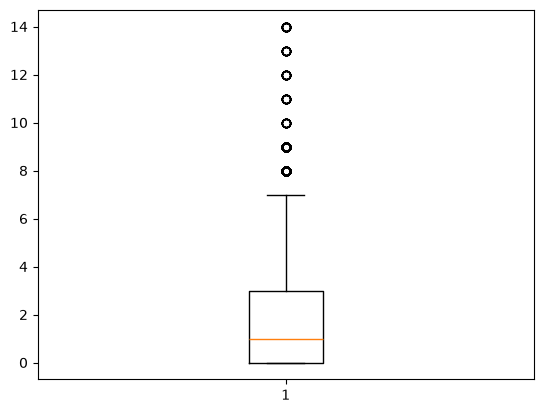

In [110]:
plt.boxplot(test['Work_Experience'])
plt.show

In [111]:
def remove_outliers_iqr(data, column_name='value'):
    Q1 = test[column_name].quantile(0.25)
    Q3 = test[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return test[(train[column_name] >= lower) & (test[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(test, column_name='Work_Experience')

print(test.shape, cleaned_df.shape)


(2605, 17) (2249, 17)


C:\Users\abdoa\AppData\Local\Temp\ipykernel_15532\905192842.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  return test[(train[column_name] >= lower) & (test[column_name] <= upper)]


In [112]:
X_train=train.drop(['Segmentation'],axis=1)
y_train=train['Segmentation']

In [113]:
X_test=test.drop(['Segmentation'],axis=1)
y_test=test['Segmentation']

In [114]:
from sklearn.preprocessing import StandardScaler
std=StandardScaler()

X_train[['Age','Work_Experience']] = std.fit_transform(train[['Age','Work_Experience']]) # train
X_test[['Age','Work_Experience']] = std.transform(test[['Age','Work_Experience']]) # test

In [115]:
X_train.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,-1.306226,-0.46786,0,4.0,4.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-0.337950,-0.46786,1,3.0,4.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.417049,-0.46786,0,1.0,6.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.417049,-0.77042,2,2.0,6.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.216916,-0.46786,2,6.0,6.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [116]:
X_test.head()

,Age,Work_Experience,Spending_Score,Family_Size,Var_1,Gender_Male,Ever_Married_Yes,Graduated_Yes,Profession_Doctor,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing
0,-0.458985,-0.770420,0,1.0,6.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,-0.398468,1.650064,1,4.0,6.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.538084,-0.770420,0,1.0,6.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.932911,2.557746,2,2.0,6.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,-1.487778,-0.467860,0,4.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
